In [17]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import torch.nn as nn
import matplotlib.pyplot as plt
from torchsummary import summary

transform = transforms.ToTensor()

train_set = datasets.CIFAR10(root="./data", train=True,  download=True, transform=transform)
test_set  = datasets.CIFAR10(root="./data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
test_loader  = DataLoader(test_set,  batch_size=64, shuffle=False)

images: torch.Size([64, 3, 32, 32])
labels: torch.Size([64])
train_set: 50000 | test_set: 10000
train_loader: 782
10 first labels: tensor([1, 9, 9, 0, 1, 1, 6, 0, 1, 1])
Class names: ['automobile', 'truck', 'truck', 'airplane', 'automobile', 'automobile', 'frog', 'airplane', 'automobile', 'automobile']


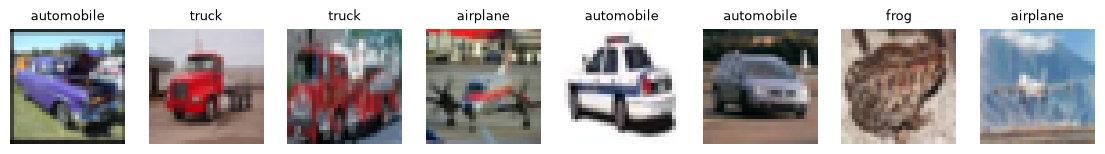

In [18]:
images, labels = next(iter(train_loader))

print("images:", images.shape)
print("labels:", labels.shape)

print("train_set:", len(train_set), "| test_set:", len(test_set))
print("train_loader:", len(train_loader))

print("10 first labels:", labels[:10])
print("Class names:", [train_set.classes[i] for i in labels[:10]])

fig, axes = plt.subplots(1, 8, figsize=(14, 2.5))
for i, ax in enumerate(axes):
    ax.imshow(images[i].permute(1, 2, 0), cmap="gray")
    ax.set_title(train_set.classes[labels[i]], fontsize=9)
    ax.axis("off")
plt.show()

In [21]:
class MLP(nn.Module):
    def __init__(self, input_dim, hidden, num_classes=10):
        super().__init__()
        layers = []
        in_dim = input_dim

        for h in hidden:
            layers.append(nn.Linear(in_dim, h))
            layers.append(nn.ReLU())
            in_dim = h
        
        layers.append(nn.Linear(in_dim, num_classes))


        self.flatten = nn.Flatten()
        self.net = nn.Sequential(*layers)
    
        # Initialize He for Linear layers
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.kaiming_uniform_(m.weight, nonlinearity="relu")
                nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.flatten(x)
        x = self.net(x)
        return x

input_dim = 3 * 32 * 32
model1 = MLP(input_dim, [256], 10)
model2 = MLP(input_dim, [256, 256], 10)
model3 = MLP(input_dim, [256, 256, 256], 10)

summary(model1, input_size=(3, 32, 32), device="cpu")
summary(model2, input_size=(3, 32, 32), device="cpu")
summary(model3, input_size=(3, 32, 32), device="cpu")

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
           Flatten-1                 [-1, 3072]               0
            Linear-2                  [-1, 256]         786,688
              ReLU-3                  [-1, 256]               0
            Linear-4                   [-1, 10]           2,570
Total params: 789,258
Trainable params: 789,258
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.01
Forward/backward pass size (MB): 0.03
Params size (MB): 3.01
Estimated Total Size (MB): 3.05
----------------------------------------------------------------
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
           Flatten-1                 [-1, 3072]               0
            Linear-2                  [-1, 256]         786,688
              ReLU-3                  [-1

In [22]:
device = "mps" if torch.backends.mps.is_available() else "cpu"
print("device:", device)

criterion = nn.CrossEntropyLoss()

device: mps


In [24]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, correct, n = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        logits = model(images)  # forward
        loss = criterion(logits, labels) # compute loss

        optimizer.zero_grad()   # clear gradient
        loss.backward()         # backprop
        optimizer.step()        # update params

        total_loss += loss.item() * images.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        n += images.size(0)
    return total_loss / n, correct / n

def evaluate(model, loader, criterion, device):
    model.eval()                                   # chế độ đánh giá
    total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():                          # không tính gradient
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            logits = model(images)
            loss = criterion(logits, labels)
            total_loss += loss.item() * images.size(0)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            n += images.size(0)
    return total_loss / n, correct / n

In [ ]:
configs = {"Case 2": [256], "Case 3": [256, 256], "Case 4": [256, 256, 256]}
results = {}

for name, hidden in configs.items():
    torch.manual_seed(42)
    model = MLP(input_dim, hidden).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

    for epoch in range(1, 11):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        te_loss, te_acc = evaluate(model, test_loader, criterion, device)
    print(f"{name} {hidden}: train acc {tr_acc:.4f} | test acc {te_acc:.4f}")
    results[name] = te_acc

Case 2 [256]: train acc 0.5001 | test acc 0.4812
Case 3 [256, 256]: train acc 0.5220 | test acc 0.4976
Case 4 [256, 256, 256]: train acc 0.5321 | test acc 0.5075
